# PyTorch 입문 — 이탈(churn) 예측 · 로지스틱 · BCELoss

고객이 서비스를 **그만둘지(이탈)** 를 예/아니오로 맞춥니다.  
`StandardScaler` · 모델 `in_dim→32→1` · Sigmoid · `BCELoss` · Adam · `DataLoader`로 학습합니다.  
이론 복습: [`../session10.md`](../session10.md)

> **이 노트북이 하는 일**  
> CSV → feature/label(`churn`) → train/test → StandardScaler(fit=train만) → 텐서 → Linear+ReLU+Sigmoid → BCELoss · Adam → 배치 학습 → 임계값 0.5 정확도.

환경: `torch-env` 커널을 쓰는 것을 권장합니다. `pandas` · `scikit-learn`이 필요합니다.


## 1. import


In [20]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
from sklearn.model_selection import train_test_split # 데이터를 훈련 데이터와 테스트 데이터로 나누는 함수
from sklearn.preprocessing import StandardScaler # 데이터를 평균 0 · 표준편차 1로 맞추는 함수
from torch.utils.data import TensorDataset, DataLoader


## 2. CSV 로드 · feature · label

경로는 노트북 기준 상대경로 `data/ChurnData.csv`입니다.  
`churn`은 이탈 여부(1=이탈, 0=유지)입니다.


In [21]:
df = pd.read_csv("data/ChurnData.csv")
print(df.shape)
print("결측 합계:", df.isna().sum().sum())

feature = df.drop(["churn"], axis=1).values.astype("float32") # churn 열을 제외한 모든 열을 feature로 설정
label = df["churn"].values.astype("float32") # churn 열을 label로 설정
print(feature.shape, label.shape) # (5000, 11), (5000,)


(200, 28)
결측 합계: 0
(200, 27) (200,)


## 3. train / test 나누기

테스트는 학습에 안 쓴 점수표입니다.


In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    feature, label, test_size=0.2, random_state=1 # test_size=0.2: 20%를 테스트 데이터로 사용, random_state=1: 랜덤 시드 설정
)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape) # (160, 27) (40, 27) (160,) (40,)


(160, 27) (40, 27) (160,) (40,)


## 4. StandardScaler — fit은 train만

`StandardScaler`는 각 열을 **평균 0 · 표준편차 1**로 맞춥니다.  
`MinMaxScaler`는 0~1로 압축합니다. 표·숫자 특징에는 Standard, 0~1 범위가 필요할 때 MinMax를 씁니다.  
테스트에 `fit`을 하면 테스트 평균·표준편차가 학습 전처리에 섞입니다(데이터 누수).


In [23]:
sc = StandardScaler()
X_train = sc.fit_transform(X_train)  # 학습에서만 평균·표준편차 기억
X_test = sc.transform(X_test)  # 테스트는 transform만 (fit 금지)


## 5. 텐서 · `view(-1, 1)`

정답 열 수를 모델 출력 1개와 맞춥니다. `view(-1, 1)`은 "행은 알아서, 열은 1개"입니다.


In [24]:
X_train_tensor = torch.FloatTensor(X_train) # X_train을 텐서로 변환
X_test_tensor = torch.FloatTensor(X_test) # X_test을 텐서로 변환
y_train_tensor = torch.FloatTensor(y_train).view(-1, 1) # y_train을 텐서로 변환, view(-1, 1)은 "행은 알아서, 열은 1개"입니다.
y_test_tensor = torch.FloatTensor(y_test).view(-1, 1) # y_test을 텐서로 변환, view(-1, 1)은 "행은 알아서, 열은 1개"입니다.

print(X_train_tensor.shape, y_train_tensor.shape) # torch.Size([160, 27]) torch.Size([160, 1])
print(X_test_tensor.shape, y_test_tensor.shape) # torch.Size([40, 27]) torch.Size([40, 1])


torch.Size([160, 27]) torch.Size([160, 1])
torch.Size([40, 27]) torch.Size([40, 1])


## 6. 로지스틱 모델 — `in_dim→32→1` · ReLU · Sigmoid

은닉 칸 수 32는 **2의 거듭제곱**(8, 16, 32, 64…)이라 연산이 효율적인 편입니다.  
마지막 **Sigmoid**는 출력을 0~1 확률로 만듭니다.  
Adam의 `betas`는 (관성, 보폭 조절) 역할입니다. 기본값은 `(0.9, 0.999)`입니다.


In [25]:
class LinearReg(nn.Module):
    def __init__(self, in_dim):
        super().__init__()
        # 로지스틱(확률) 분류의 기본 뼈대: 입력 → 선형 → ReLU → Sigmoid
        self.linear1 = nn.Linear(in_dim, 32)  # 입력 → 은닉 32
        self.linear2 = nn.Linear(32, 1)  # 은닉 → 확률 1개
        self.relu = nn.ReLU() #ReLU 함수: 0보다 큰 값은 그대로, 0보다 작은 값은 0으로 만듭니다.
        # ReLU 함수를 사용하는 이유 - 비선형이 필요해서, 음수→0 = ReLU가 비선형을 만듦
        self.sigmoid = nn.Sigmoid() #Sigmoid 함수: 0~1 사이의 값으로 만듭니다.

    def forward(self, x):
        x = self.relu(self.linear1(x))  # 비선형 스위치
        out = self.sigmoid(self.linear2(x))  # 0~1 확률
        return out


model = LinearReg(X_train.shape[1])
print(model)

criterion = nn.BCELoss()  # 이진(0/1) 정답과 확률의 차이, BCELoss 함수: 이진 분류 손실 함수
# lr: 한 번에 weight·bias를 얼마나 크게 고칠지
# betas 기본값 (0.9, 0.999): 관성·보폭 조절
optimizer = optim.Adam(model.parameters(), lr=0.001) # 0.001 = 1e-3
print(optimizer)


LinearReg(
  (linear1): Linear(in_features=27, out_features=32, bias=True)
  (linear2): Linear(in_features=32, out_features=1, bias=True)
  (relu): ReLU()
  (sigmoid): Sigmoid()
)
Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


## 7. TensorDataset · DataLoader

같은 고객의 특징·이탈 여부를 한 묶음으로 맞춥니다.  
한 번에 16개씩, epoch마다 순서를 섞습니다.


In [26]:
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)

print(len(train_dataset), len(train_loader))


160 10


## 8. 학습 루프

배치마다 `zero_grad` → `backward` → `step` 순서를 지킵니다.  
epoch마다 평균 loss를 리스트에 쌓아 나중에 곡선으로 그립니다.


In [27]:
epochs = 50
train_losses = []  # epoch별 평균 loss

for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    for x_batch, y_batch in train_loader:
        yhat = model(x_batch)
        loss = criterion(yhat, y_batch)

        optimizer.zero_grad()  # 이전 기울기 비우기
        loss.backward()
        optimizer.step()  # weight · bias 갱신

        running_loss += loss.item()

    avg_loss = running_loss / len(train_loader)
    train_losses.append(avg_loss)

    if epoch % 10 == 0 or epoch == epochs - 1:
        print(f"epoch {epoch:3d} | train_bce={avg_loss:.4f}")


epoch   0 | train_bce=0.7031


epoch  10 | train_bce=0.4890
epoch  20 | train_bce=0.4333
epoch  30 | train_bce=0.3960
epoch  40 | train_bce=0.3660
epoch  49 | train_bce=0.3418


## 9. 학습 loss 곡선

epoch마다 쌓은 평균 loss를 그려 학습이 잘 줄어드는지 봅니다.

c:\Users\dmsrh\miniconda3\envs\torch-env\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 54617 (\N{HANGUL SYLLABLE HAG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\dmsrh\miniconda3\envs\torch-env\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 49845 (\N{HANGUL SYLLABLE SEUB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


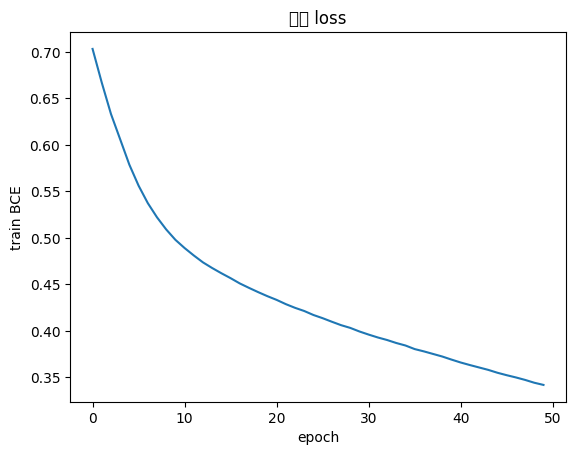

In [28]:
plt.plot(train_losses)
plt.xlabel("epoch")
plt.ylabel("train BCE")
plt.title("학습 loss")
plt.show()

## 10. 테스트 — 임계값 0.5 정확도

예측 확률이 **0.5 이상**이면 이탈(1), 아니면 유지(0)로 봅니다.  
정확도는 "맞춘 개수 / 전체"입니다.  
`flatten()`은 (N, 1)처럼 칸이 여러 줄인 배열을 한 줄로 펴서 정답·예측 길이를 맞출 때 씁니다.


In [29]:
model.eval() # 모델을 테스트 모드로 설정
with torch.no_grad(): # 기울기 없이 테스트 점수를 계산
    y_prob = model(X_test_tensor) # 모델에 X_test_tensor를 입력하여 예측값을 계산
    y_pred = (y_prob >= 0.5).float() # 예측값이 0.5 이상이면 1, 아니면 0으로 변환
    acc = (y_pred == y_test_tensor).float().mean() # 예측값과 실제값의 차이를 계산

print("예측 확률 일부:", y_prob[:5].view(-1).tolist()) # 예측값을 넘파이 배열로 변환하고, view(-1)은 1차원 배열로 변환하는 함수
print("테스트 정확도:", acc.item()) # 테스트 정확도: 0.xxx


예측 확률 일부: [0.5459397435188293, 0.7213218212127686, 0.46002376079559326, 0.24595914781093597, 0.021835459396243095]
테스트 정확도: 0.800000011920929


---

이론 복습: [`../session10.md`](../session10.md) · 이전 실습: [`10_boston_mlp.ipynb`](./10_boston_mlp.ipynb)
